In [ ]:
import torch
import torch.nn as nn
import numpy as np
import pickle, os, random

def reset_random_seeds():
    os.environ['PYTHONHASHSEED']=str(2)
    torch.manual_seed(2)
    np.random.seed(2)
    random.seed(2)
    torch.cuda.manual_seed(2)
    torch.cuda.manual_seed_all(2)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
%cd /content/drive/MyDrive

/content/drive/MyDrive


In [ ]:
with open('summ_data.pkl', "rb") as f:
  text_tok, headlines_tok = pickle.load(f)

In [ ]:
from tokenizers import ByteLevelBPETokenizer

tokenizer = ByteLevelBPETokenizer(
    "my_bpe_tokenizer/vocab.json",
    "my_bpe_tokenizer/merges.txt"
)

In [ ]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(text_tok, headlines_tok, test_size=0.15, random_state=1)

In [ ]:
MAXLEN = x_train.shape[1]
D_MODEL = 128
N_HEADS = 4
N_LAYERS = 4
FF_UNITS = D_MODEL * 3
PEAK_LR = 5e-4
END_LR = 1e-6
INIT_LR = 1e-6
WARMUP_RATE = 0.05
BATCH = 32
VOCAB_SIZE = tokenizer.get_vocab_size()

In [ ]:
!pip install torch_optimizer

In [ ]:
from torch.utils.data import TensorDataset, DataLoader
import torch_optimizer

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def create_tensor_data(x,y,batch,shuffle=True):

    x_ = torch.tensor(x,dtype=torch.long,device=device)
    y_ = torch.tensor(y,dtype=torch.long,device=device)
    data = TensorDataset(x_,y_)
    data = DataLoader(data,batch_size=batch,shuffle=shuffle)
    return data

train = create_tensor_data(x_train,y_train,BATCH)
test = create_tensor_data(x_test,y_test,BATCH * 2,shuffle=False)

In [ ]:
class CosineLRScheduler:
    def __init__(self, total_steps, peak_lr=1e-4, min_lr=1e-8, init_lr=1e-8, warmup_rate=0.05):
        """
        Custom lr scheduler. linear lr warm-up and cosine lr decay.
        :param total_steps: total training steps
        :param max_lr: peak lr value
        :param min_lr: lr decay value
        :param init_lr: initial lr value
        :param warmup_rate: number of warmup steps
        """
        self.min_lr = min_lr
        self.init_lr = init_lr
        self.total_setps = total_steps
        self.warmup = int(total_steps * warmup_rate)
        self.decay = total_steps - self.warmup
        self.warmup_lr = np.linspace(init_lr, peak_lr, self.warmup)
        self.max_lr = self.warmup_lr[-1]


    def __call__(self, step):

        if step <= self.warmup:

            lr = self.warmup_lr[step - 1]
        else:
            step = step - self.warmup
            lr = self.min_lr + 0.5 * (self.max_lr - self.min_lr) * (1 + np.cos(step * np.pi / self.decay))

        return lr

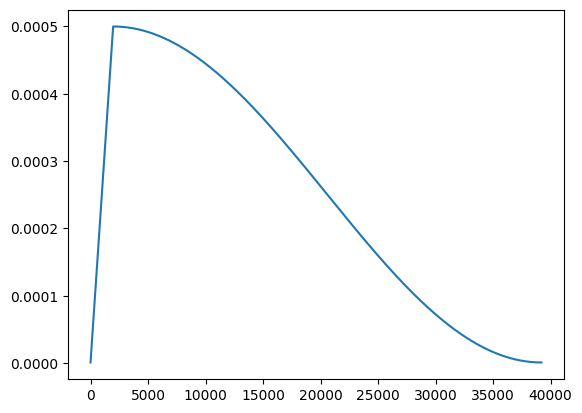

In [ ]:
import matplotlib.pyplot as plt


EPOCHS = 15
train_steps = len(train) * EPOCHS

lr_scheduler = CosineLRScheduler(train_steps,
                                 peak_lr=PEAK_LR,min_lr=END_LR,
                                 init_lr=INIT_LR,warmup_rate=WARMUP_RATE)

plt.plot([lr_scheduler(i) for i in range(1,train_steps+1)])

In [ ]:
import math
import numpy as np
import torch
from torch import nn

class FactorizeEmbeddingLayer(nn.Module):
    def __init__(self, vocab_size, d_model, maxlen):
        super().__init__()
        self.vocab_size = vocab_size
        self.d_model = d_model
        self.maxlen = maxlen

        self.emb = nn.Embedding(self.vocab_size, self.d_model // 2)
        self.fact_layer = nn.Linear(self.d_model // 2, self.d_model)
        self.pos_encoding = nn.Parameter(self._positional_encoding(), requires_grad=True)

    def _positional_encoding(self):
        pos = np.zeros((self.maxlen, self.d_model), dtype=np.float32)
        for p in range(self.maxlen):
            for i in range(self.d_model):
                exponent = 2 * (i // 2) / self.d_model
                angle = p / (10000 ** exponent)
                if i % 2 == 0:
                    pos[p, i] = np.sin(angle)
                else:
                    pos[p, i] = np.cos(angle)
        return torch.tensor(pos, dtype=torch.float32)

    def forward(self, x):
        mask = (x == 1)
        x = self.fact_layer(self.emb(x)) + self.pos_encoding[:x.shape[1], :].unsqueeze(0)
        return x, mask


class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads, look_ahead_mask=False):
        super().__init__()
        self.d_model = d_model
        self.n_heads = n_heads
        self.attn_scores = None
        self.d_head = self.d_model // self.n_heads
        self.look_ahead_mask = look_ahead_mask

        self.q = nn.Linear(self.d_model, self.d_model, False)
        self.k = nn.Linear(self.d_model, self.d_model, False)
        self.v = nn.Linear(self.d_model, self.d_model, False)

        self.attn_drop = nn.Dropout(0.1)
        self.lin = nn.Linear(d_model, d_model)
        self.lin_drop = nn.Dropout(0.1)

    def _split_heads(self, x):
        x = torch.reshape(x, shape=(x.shape[0], x.shape[1], self.n_heads, self.d_head))
        return torch.permute(x, (0, 2, 1, 3))

    def forward(self, x):
        x, mask = x
        q, k, v = x
        mask = mask[:, torch.newaxis, torch.newaxis, :]
        maxlen = q.shape[1]
        b = q.shape[0]

        q = self.q(q)
        k = self.k(k)
        v = self.v(v)

        q = self._split_heads(q)
        k = self._split_heads(k)
        v = self._split_heads(v)

        k_trans = torch.permute(k, (0, 1, 3, 2))
        attn = torch.matmul(q, k_trans) / (self.d_head ** 0.5)
        attn = torch.where(mask, -1e8, attn)

        if self.look_ahead_mask:
            look_ahead_mask = torch.triu(torch.ones(maxlen, maxlen, device=attn.device), diagonal=1).bool()
            attn = attn.masked_fill(look_ahead_mask, -1e8)

        attn = torch.softmax(attn, -1)
        self.attn_scores = attn
        attn = self.attn_drop(attn)

        x = torch.matmul(attn, v)
        x = x.permute(0, 2, 1, 3)
        x = torch.reshape(x, (b, maxlen, self.d_model))
        x = self.lin(x)

        return self.lin_drop(x)


class FeedForward(nn.Module):
    def __init__(self, d_model, ff_units):
        super().__init__()
        self.d_model = d_model
        self.ff_units = ff_units

        self.ff1 = nn.Linear(d_model, ff_units)
        self.ff2 = nn.Linear(ff_units, d_model)
        self.drop = nn.Dropout(0.1)

    def forward(self, x):
        x = self.ff1(x)
        x = torch.nn.functional.gelu(x)
        x = self.ff2(x)
        x = self.drop(x)
        return x


class EncoderLayer(nn.Module):
    def __init__(self, d_model, n_heads, ff_units):
        super().__init__()
        self.d_model = d_model
        self.n_heads = n_heads
        self.ff_units = ff_units

        self.attn_layer = MultiHeadAttention(d_model, n_heads)
        self.ff_layer = FeedForward(d_model, ff_units)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)

    def forward(self, inputs):
        x, mask = inputs
        attn = self.attn_layer([[x, x, x], mask])
        x = self.norm1(attn + x)
        ff = self.ff_layer(x)
        x = self.norm2(ff + x)
        return x


class DecoderLayer(nn.Module):
    def __init__(self, d_model, n_heads, ff_units):
        super().__init__()
        self.d_model = d_model
        self.n_heads = n_heads
        self.ff_units = ff_units

        self.self_attn_layer = MultiHeadAttention(d_model, n_heads, look_ahead_mask=True)
        self.cross_attn_layer = MultiHeadAttention(d_model, n_heads)
        self.ff_layer = FeedForward(d_model, ff_units)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.norm3 = nn.LayerNorm(d_model)

    def forward(self, inputs):
        x, mask, en_out, en_mask = inputs
        self_attn = self.self_attn_layer(((x, x, x), mask))
        x = self.norm1(self_attn + x)
        cross_attn = self.cross_attn_layer(((x, en_out, en_out), en_mask))
        x = self.norm2(x + cross_attn)
        ff = self.ff_layer(x)
        x = self.norm3(x + ff)
        return x

In [ ]:
class AlbertEncstdDecTransformer(nn.Module):
    def __init__(self, vocab_size, d_model, n_heads, n_layers, ff_units, maxlen):
        super().__init__()
        self.n_layers = n_layers

        self.src_embedding = FactorizeEmbeddingLayer(vocab_size, d_model, maxlen)
        self.tgt_embedding = FactorizeEmbeddingLayer(vocab_size, d_model, maxlen)

        self.shared_encoder_layer = EncoderLayer(d_model, n_heads, ff_units)

        self.decoder_layers = nn.ModuleList([
            DecoderLayer(d_model, n_heads, ff_units) for _ in range(n_layers)
        ])

        self.fc_out = nn.Linear(d_model, vocab_size)

    def forward(self, src, tgt):
        src_emb, src_mask = self.src_embedding(src)
        tgt_emb, tgt_mask = self.tgt_embedding(tgt)

        en_out = src_emb
        for _ in range(self.n_layers):
            en_out = self.shared_encoder_layer([en_out, src_mask])

        de_out = tgt_emb
        for dec in self.decoder_layers:
            de_out = dec([de_out, tgt_mask, en_out, src_mask])

        return self.fc_out(de_out)

reset_random_seeds()
albert_encoder_model = AlbertEncstdDecTransformer(
    vocab_size=VOCAB_SIZE,
    d_model=D_MODEL,
    n_heads=N_HEADS,
    n_layers=N_LAYERS,
    ff_units=FF_UNITS,
    maxlen=MAXLEN
).to(device)

In [ ]:
#albert_encoder_model.state_dict()

In [ ]:
def count_parameters(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

print(f"ALBERT style Encoder and Standerd Decoder Transformer Parameters: {count_parameters(albert_encoder_model):,}")

ALBERT style Encoder and Standerd Decoder Transformer Parameters: 4,993,048


In [ ]:
def summarize(src_ids, max_len=32):
    albert_encoder_model.eval()

    src_tensor = torch.tensor([src_ids], dtype=torch.long, device=device)

    sos_id = tokenizer.token_to_id("<s>")
    eos_id = tokenizer.token_to_id("</s>")

    tgt_ids = [sos_id]

    with torch.no_grad():
        for _ in range(max_len):
            tgt_tensor = torch.tensor([tgt_ids], dtype=torch.long, device=device)
            output = albert_encoder_model(src_tensor, tgt_tensor)

            next_token = output[0, -1, :].argmax().item()

            if next_token == eos_id:
                break

            tgt_ids.append(next_token)

    raw_text = tokenizer.decode(tgt_ids)
    clean_text = raw_text.replace("<s>", "").replace("</s>", "").replace("<pad>", "").strip()
    return clean_text

def clean_decode(tokens):
    raw = tokenizer.decode(tokens.tolist())
    return raw.replace("<s>", "").replace("</s>", "").replace("<pad>", "").strip()


In [ ]:
from tqdm.auto import tqdm

def train_model(data, model, lr_scheduler, EPOCHS=10, file='saved_weights.pt'):
    train, valid = data

    opt = torch.optim.AdamW(model.parameters(), weight_decay=0.01)
    pad_id = 1
    loss_fn = nn.CrossEntropyLoss(ignore_index=pad_id)

    step = 1
    best_val_loss = float('inf')
    losses = {'train': [], 'valid': []}

    for epoch in range(1, EPOCHS + 1):
        print(f"Epoch {epoch}/{EPOCHS}")

        model.train()
        train_loss = 0.0

        pbar = tqdm(train, desc="Training", unit="batch")
        for x, y in pbar:
            lr = lr_scheduler(step)
            for param_group in opt.param_groups:
                param_group['lr'] = lr

            src = x.long()
            tgt = y.long()
            tgt_input = tgt[:, :-1]
            tgt_label = tgt[:, 1:]

            opt.zero_grad()
            pred = model(src, tgt_input)
            batch_loss = loss_fn(pred.reshape(-1, VOCAB_SIZE), tgt_label.reshape(-1))
            batch_loss.backward()
            opt.step()

            train_loss += batch_loss.item()
            step += 1

            pbar.set_postfix({"batch_loss": f"{batch_loss.item():.4f}", "lr": f"{lr:.2e}"})

        avg_train_loss = round(train_loss / len(train), 4)
        losses['train'].append(avg_train_loss)
        print(f"Train Loss = {avg_train_loss}")

        model.eval()
        val_loss = 0.0

        with torch.no_grad():
            for x, y in valid:
                src = x.long()
                tgt = y.long()
                tgt_input = tgt[:, :-1]
                tgt_label = tgt[:, 1:]

                pred = model(src, tgt_input)
                batch_loss = loss_fn(pred.reshape(-1, VOCAB_SIZE), tgt_label.reshape(-1))
                val_loss += batch_loss.item()

        avg_val_loss = round(val_loss / len(valid), 4)
        losses['valid'].append(avg_val_loss)
        print(f"Val Loss   = {avg_val_loss}")

        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            torch.save(model.state_dict(), file)
            print(f"-- Best weights saved to {file} (Val Loss: {best_val_loss})")

        print("-" * 50)

        for i in [0, 1]:
          article = clean_decode(x_test[i])
          real_headline = clean_decode(y_test[i])
          predicted_headline = summarize(x_test[i].tolist())

          print(f"--- SAMPLE {i+1} ---")
          print("ARTICLE:   ", article[:150] + "...")
          print("ACTUAL:    ", real_headline)
          print("PREDICTED: ", predicted_headline)
          print()

        print('------------------------------------------------------------------------------')


    return losses

In [ ]:
train_model((train, test), albert_encoder_model, lr_scheduler, EPOCHS=EPOCHS)

Epoch 1/15


Training:   0%|          | 0/2614 [00:00<?, ?batch/s]

Train Loss = 6.9354
Val Loss   = 5.839
-- Best weights saved to saved_weights.pt (Val Loss: 5.839)
--------------------------------------------------
--- SAMPLE 1 ---
ARTICLE:    japan ' s largest toilet maker toto has opened a high - tech experiential showroom called ' concept 190 ' in san francisco , where it has invited peop...
ACTUAL:     high - tech toilet maker invites people to pee in new showroom
PREDICTED:  india to be most powerful ' s largest - driving to be held

--- SAMPLE 2 ---
ARTICLE:    malaysia on thursday said all its citizens are banned from travelling to north korea due to escalating tensions on the korean peninsula following nort...
ACTUAL:     malaysia bans travel to north korea over escalating tensions
PREDICTED:  india to be its first time to be in us

------------------------------------------------------------------------------
Epoch 2/15


Training:   0%|          | 0/2614 [00:00<?, ?batch/s]

Train Loss = 5.3089
Val Loss   = 4.9188
-- Best weights saved to saved_weights.pt (Val Loss: 4.9188)
--------------------------------------------------
--- SAMPLE 1 ---
ARTICLE:    japan ' s largest toilet maker toto has opened a high - tech experiential showroom called ' concept 190 ' in san francisco , where it has invited peop...
ACTUAL:     high - tech toilet maker invites people to pee in new showroom
PREDICTED:  japan ' s largest - shaped ' s ' smart ' to ' to '

--- SAMPLE 2 ---
ARTICLE:    malaysia on thursday said all its citizens are banned from travelling to north korea due to escalating tensions on the korean peninsula following nort...
ACTUAL:     malaysia bans travel to north korea over escalating tensions
PREDICTED:  china to allow north korea to north korea

------------------------------------------------------------------------------
Epoch 3/15


Training:   0%|          | 0/2614 [00:00<?, ?batch/s]

... (22 outputs left out)

Train Loss = 2.3283
Val Loss   = 3.3902
-- Best weights saved to saved_weights.pt (Val Loss: 3.3902)
--------------------------------------------------
--- SAMPLE 1 ---
ARTICLE:    japan ' s largest toilet maker toto has opened a high - tech experiential showroom called ' concept 190 ' in san francisco , where it has invited peop...
ACTUAL:     high - tech toilet maker invites people to pee in new showroom
PREDICTED:  japan ' s largest seals to be pee with big machine

--- SAMPLE 2 ---
ARTICLE:    malaysia on thursday said all its citizens are banned from travelling to north korea due to escalating tensions on the korean peninsula following nort...
ACTUAL:     malaysia bans travel to north korea over escalating tensions
PREDICTED:  malaysia bans citizens from n korea to resolve missile

------------------------------------------------------------------------------
Epoch 15/15


Training:   0%|          | 0/2614 [00:00<?, ?batch/s]

Train Loss = 2.3092
Val Loss   = 3.389
-- Best weights saved to saved_weights.pt (Val Loss: 3.389)
--------------------------------------------------
--- SAMPLE 1 ---
ARTICLE:    japan ' s largest toilet maker toto has opened a high - tech experiential showroom called ' concept 190 ' in san francisco , where it has invited peop...
ACTUAL:     high - tech toilet maker invites people to pee in new showroom
PREDICTED:  japan ' s largest seals to be pee with big machine

--- SAMPLE 2 ---
ARTICLE:    malaysia on thursday said all its citizens are banned from travelling to north korea due to escalating tensions on the korean peninsula following nort...
ACTUAL:     malaysia bans travel to north korea over escalating tensions
PREDICTED:  malaysia bans citizens from n korea for n korea

------------------------------------------------------------------------------


{'train': [6.9354,
  5.3089,
  4.5411,
  4.0374,
  3.6658,
  3.3711,
  3.133,
  2.9364,
  2.7715,
  2.6345,
  2.5236,
  2.4372,
  2.3718,
  2.3283,
  2.3092],
 'valid': [5.839,
  4.9188,
  4.4499,
  4.1348,
  3.9318,
  3.7707,
  3.6446,
  3.5633,
  3.4951,
  3.4509,
  3.4228,
  3.4059,
  3.3946,
  3.3902,
  3.389]}

In [ ]:
def summarize(src_ids, max_len=32):
    albert_encoder_model.eval()

    src_tensor = torch.tensor([src_ids], dtype=torch.long, device=device)

    sos_id = tokenizer.token_to_id("<s>")
    eos_id = tokenizer.token_to_id("</s>")

    tgt_ids = [sos_id]

    with torch.no_grad():
        for _ in range(max_len):
            tgt_tensor = torch.tensor([tgt_ids], dtype=torch.long, device=device)
            output = albert_encoder_model(src_tensor, tgt_tensor)

            next_token = output[0, -1, :].argmax().item()

            if next_token == eos_id:
                break

            tgt_ids.append(next_token)

    raw_text = tokenizer.decode(tgt_ids)
    clean_text = raw_text.replace("<s>", "").replace("</s>", "").replace("<pad>", "").strip()
    return clean_text

def clean_decode(tokens):
    raw = tokenizer.decode(tokens.tolist())
    return raw.replace("<s>", "").replace("</s>", "").replace("<pad>", "").strip()

for i in [0, 1]:
    article = clean_decode(x_test[i])
    real_headline = clean_decode(y_test[i])
    predicted_headline = summarize(x_test[i].tolist())

    print(f"--- SAMPLE {i+1} ---")
    print("ARTICLE:   ", article[:150] + "...")
    print("ACTUAL:    ", real_headline)
    print("PREDICTED: ", predicted_headline)
    print()

--- SAMPLE 1 ---
ARTICLE:    japan ' s largest toilet maker toto has opened a high - tech experiential showroom called ' concept 190 ' in san francisco , where it has invited peop...
ACTUAL:     high - tech toilet maker invites people to pee in new showroom
PREDICTED:  japan ' s largest seals to be pee with big machine

--- SAMPLE 2 ---
ARTICLE:    malaysia on thursday said all its citizens are banned from travelling to north korea due to escalating tensions on the korean peninsula following nort...
ACTUAL:     malaysia bans travel to north korea over escalating tensions
PREDICTED:  malaysia bans citizens from n korea for n korea



In [ ]:
!pip install rouge-score

In [ ]:
from rouge_score import rouge_scorer
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
from tqdm.auto import tqdm

scorer = rouge_scorer.RougeScorer(['rouge1', 'rouge2', 'rougeL'], use_stemmer=True)
smooth = SmoothingFunction().method1

rouge1_list = []
rouge2_list = []
rougel_list = []

bleu1_list = []
bleu2_list = []
bleu3_list = []
bleu4_list = []

NUM_EVAL = 1000

for i in tqdm(range(NUM_EVAL), desc="Evaluating"):
    ref = clean_decode(y_test[i])
    pred = summarize(x_test[i].tolist())

    if not pred.strip():
        continue

    scores = scorer.score(ref, pred)
    rouge1_list.append(scores['rouge1'].fmeasure)
    rouge2_list.append(scores['rouge2'].fmeasure)
    rougel_list.append(scores['rougeL'].fmeasure)

    ref_tokens = ref.split()
    pred_tokens = pred.split()

    b1 = sentence_bleu([ref_tokens], pred_tokens, weights=(1.0, 0, 0, 0), smoothing_function=smooth)
    b2 = sentence_bleu([ref_tokens], pred_tokens, weights=(0.5, 0.5, 0, 0), smoothing_function=smooth)
    b3 = sentence_bleu([ref_tokens], pred_tokens, weights=(1/3, 1/3, 1/3, 0), smoothing_function=smooth)
    b4 = sentence_bleu([ref_tokens], pred_tokens, weights=(0.25, 0.25, 0.25, 0.25), smoothing_function=smooth)

    bleu1_list.append(b1)
    bleu2_list.append(b2)
    bleu3_list.append(b3)
    bleu4_list.append(b4)

print("\n========== ALBERT ENCODER + STANDARD DECODER TRANSFORMER RESULTS ==========")
print(f"BLEU-1:      {sum(bleu1_list) / len(bleu1_list):.4f}")
print(f"BLEU-2:      {sum(bleu2_list) / len(bleu2_list):.4f}")
print(f"BLEU-3:      {sum(bleu3_list) / len(bleu3_list):.4f}")
print(f"BLEU-4:      {sum(bleu4_list) / len(bleu4_list):.4f}")
print("-----------------------------------------------------------")
print(f"ROUGE-1 F1:  {sum(rouge1_list) / len(rouge1_list):.4f}")
print(f"ROUGE-2 F1:  {sum(rouge2_list) / len(rouge2_list):.4f}")
print(f"ROUGE-L F1:  {sum(rougel_list) / len(rougel_list):.4f}")
print("===========================================================")

Evaluating:   0%|          | 0/1000 [00:00<?, ?it/s]


========== ALBERT ENCODER + STANDARD DECODER TRANSFORMER RESULTS ==========
BLEU-1:      0.3578
BLEU-2:      0.2280
BLEU-3:      0.1511
BLEU-4:      0.1065
-----------------------------------------------------------
ROUGE-1 F1:  0.3866
ROUGE-2 F1:  0.1571
ROUGE-L F1:  0.3517


In [ ]:
import json

results = {
    "model_name": "albert_encoder_standard_decoder",
    "num_eval_samples": NUM_EVAL,
    "metrics": {
        "BLEU-1": round(sum(bleu1_list) / len(bleu1_list), 4),
        "BLEU-2": round(sum(bleu2_list) / len(bleu2_list), 4),
        "BLEU-3": round(sum(bleu3_list) / len(bleu3_list), 4),
        "BLEU-4": round(sum(bleu4_list) / len(bleu4_list), 4),
        "ROUGE-1_F1": round(sum(rouge1_list) / len(rouge1_list), 4),
        "ROUGE-2_F1": round(sum(rouge2_list) / len(rouge2_list), 4),
        "ROUGE-L_F1": round(sum(rougel_list) / len(rougel_list), 4)
    }
}

json_filename = "albert_encoder_summ_results.json"

with open(json_filename, "w") as f:
    json.dump(results, f, indent=4)

print(f"\nScores successfully saved to '{json_filename}'!")


Scores successfully saved to 'albert_encoder_summ_results.json'!


In [ ]:
torch.save(albert_encoder_model.state_dict(), "albert_encoder_summ_transformer.pt")
print("ALBERT Encoder Model saved!")

ALBERT Encoder Model saved!
